# Hausaufgabe 2 - Audiosignale (100 Punkte)


Namen: [Marta Berdnik, Theodor Neroda]

Gruppe: [28]

### Worum gehts?
In dieser Hausaufgabe beschäftigt ihr euch mit der Erstellung, Bearbeitung und Darstellung von Audiosignalen.

Am Ende dieser Hausaufgabe könnt ihr:
- Einen Synthesizer programmieren, mit dem sich einfache Melodien und Effekte generieren lassen 
- WAV-Audiodateien lesen, schreiben und ihre Eigenschaften herausfinden
- Störsignale in einem Musikstück identifizieren und entfernen

---

Diese Importe und Variablen werden später in den Aufgaben verwendet.

**Wichtig!**: Verwendet für die später von euch generierten Signale immer die hier definierten Konstanten.

*Hier muss nichts verändert werden.*

In [1]:
# Hier gibt es nichts zu tun ;)

# Benötigte Bibliotheken
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.fft import fft, ifft, fftfreq
import os

# Globale Variablen, die später im Code verwendet werden
ABTASTRATE = 44100  # Abtastrate in Samples pro Sekunde
AMPLITUDE = 1.0  # Amplitude des Signals
FREQS = {  # Beispielfrequenzen für Töne
    "C3": 130.81,
    "C#3": 138.59,
    "D3": 146.83,
    "D#3": 155.56,
    "E3": 164.81,
    "F3": 174.61,
    "F#3": 185.00,
    "G3": 196.00,
    "G#3": 207.65,
    "A3": 220.00,
    "A#3": 233.08,
    "H3": 246.94,
    "C4": 261.63,
    "C#4": 277.18,
    "D4": 293.66,
    "D#4": 311.13,
    "E4": 329.63,
    "F4": 349.23,
    "F#4": 369.99,
    "G4": 392.00,
    "G#4": 415.30,
    "A4": 440.00,
    "A#4": 466.16,
    "H4": 493.88,
    "C5": 523.25,
    "C#5": 554.37,
    "D5": 587.33,
    "D#5": 622.25,
    "E5": 659.25,
    "F5": 698.46,
    "F#5": 739.99,
    "G5": 783.99,
    "G#5": 830.61,
    "A5": 880.00,
    "A#5": 932.33,
    "H5": 987.77,
}

## Aufgabe 1 - Töne erzeugen (10 Punkte)

Für den Bau des Synthesizer müssen zuerst einfache Töne generiert werden können. In dieser Aufgabe wird ein einfacher Wellengenerator implementiert, der ein Sinussignal generiert.

Implementiert dazu die vorgegebenen Funktionen gemäß der Beschreibung.

### Tipp
Schaut euch genau bei dieser Hausaufgabe genau die Definition der Funktionen an:
- Die Parameter sind im *Docstring* (also dem großen Kommentar unter dem Funktionskopf) genauer beschrieben. So ist `freq` vom Typ `float` und gibt die Frequenz der Welle in Hz an.
- Standardparameter, wie z.B. `fade: bool = True` müssen beim Aufruf nicht zwingend angegeben werden. Nutzt entweder die vorgegebenen Standardwerte oder probiert gerne selbst aus!
- Den Rückgabetyp findet ihr hinter dem Pfeil am Ende des Funktionskopfes (z.B. `np.ndarray`). Sollte hier `None` angegeben sein, gibt eure Funktion nichts zurück.
- In Visual Studio Code könnt ihr immer, wenn eure Funktion im Code auftaucht, mit eurem Mauszeiger über den Funktionsnamen gehen, um den Docstring anzuzeigen.

In [4]:
def welle_generieren(
    freq: float,
    dauer: float,
    fade: bool = True,
    fade_schwelle: int = 441,
) -> np.ndarray:
    """
    Generiert eine Sinuswelle mit den angegebenen Parametern und gibt diese zurück.

    Parameters:
        `freq`: Frequenz der Welle in Hz
        `dauer`: Dauer des Signals in Sekunden
        `fade`: Ob Fade in und Fade out angewendet werden soll (vermeidet Knacken)
        `fade_schwelle`: Anzahl der Samples für Fade in und Fade out

    Returns:
        Numpy Array mit den Samples der Sinuswelle
    """

    # TODO: Implementiere die Funktion, indem du
    # 1. Ein Wellensignal mit der übergebenen Frequenz und Dauer generierst.
    #    AMPLITUDE und ABTASTRATE sind durch die globalen Variablen gegeben.
    #timestamps at 0 to dauer, false for concatenate, total number of sdamples via iont; y evaluates a sine wave (формула)
    x = np.linspace(0, dauer, int(ABTASTRATE * dauer), endpoint=False)
    y = AMPLITUDE * np.sin((2 * np.pi) * freq * x)
    

    # 2. Implementiere einen Fade-In und Fade-Out Effekt, um Knacken in der Audiodatei zu vermeiden.
    #    Bei einer fade_schwelle von 32 Samples soll das Signal in den ersten und letzten 32 Samples linear lauter, bzw. leiser werden.
    #    Dafür könnt ihr den linearen Verlauf mit np.linspace() erstellen und mit den entsprechenden Bereichen im Signal multiplizieren.
    #не 32 тк не работало иначе под конец; ramp up start/stop,  
    if fade:
        fade_in = np.linspace(0, 1, fade_schwelle)
        fade_out = np.linspace(1, 0, fade_schwelle)

        y[:fade_schwelle] = y[:fade_schwelle] * fade_in
        y[-fade_schwelle:] = y[-fade_schwelle:] * fade_out

    return y



def signal_speichern(dateiname: str, signal: np.ndarray) -> None:
    """
    Speichert das Signal in einer WAV-Datei.
    Das Signal wird gemäß der Konvention normalisiert und als Numpy Array vom Typ np.int16 gespeichert.

    Parameters:
        `filename`: Dateiname der WAV-Datei
        `signal`: Samples des Signals als Numpy Array
    """

    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Das Signal auf den Bereich -32767 bis 32767 normalisierst (WAV-Konvention als 16-Bit Integer).
    #    Dies ist notwendig, damit die WAV-Datei später korrekt abgespielt werden kann.
    # 2. Das Signal in den Datentyp np.int16 konvertierst.
    #how loud the loudest sample is, dividing (та же цифра = 1/-1) creates the ceiling
    max_val = np.max(np.abs(signal))
    if max_val > 0:
        normalized_signal = (signal / max_val) * 32767
    else:
        normalized_signal = signal
    
    
    normalized_signal = normalized_signal.astype(np.int16)
   
    #    Tipp: mein_numpy_array = mein_numpy_array.astype(mein_typ) wandelt ein mein_numpy_array in den Typ mein_typ um.
    #
    # 2. Die WAV-Datei mit der Abtastrate ABTASTRATE speicherst.
    wavfile.write(dateiname, ABTASTRATE, normalized_signal)
    # ------------------------------------------------
    # ------------------------------------------------

In [5]:
# Platzhalter
frequenz = FREQS["C4"]
dauer = 2

# TODO: Frequenz und Dauer des zu generierenden Ton festlegen.
#       Die Frequenz soll aus der globalen Variable FREQS entnommen werden.
# ------------------------------------------------
# ------------------------------------------------

# Sinuswelle generieren
signal_a = welle_generieren(frequenz, dauer)

# Signal abspeichern
signal_speichern("media/ton.wav", signal_a)

Wenn alles geklappt hat, sollte nun eine abspielbare Audiodatei `ton.wav` im Ordner `media` liegen.

## Aufgabe 2 - Töne aneinanderreihen (10 Punkte)
Um Melodien zu erzeugen, müssen mehrere Signale aneinandergereiht werden. In dieser Aufgabe setzt ihr Signale zu einer Sequenz zusammen und erzeugt somit einfache Melodien aus Tönen.

Implementiert dazu die vorgegebenen Funktionen gemäß der Beschreibung.

In [6]:
def signale_zusammensetzen(signale: list[np.ndarray]) -> np.ndarray:
    """
    Fügt eine Liste von Signalen aneinander und gibt das zusammengesetzte Signal zurück.

    Parameters:
        `signale`: Liste von Signalen (jeweils als Numpy Array)

    Returns:
        Numpy Array mit den zusammengesetzten Signalen
    """
    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Die Signale aus der gegebenen Liste nacheinander zusammenfügst.
    #    Nutze dazu z.B. eine geeignete Numpy-Funktion.
    return np.concatenate(signale)


def ton_zu_signal(ton: str, dauer: float) -> np.ndarray:
    """
    Erzeugt ein Signal mit der Frequenz des gegebenen Tons und Dauer und gibt dieses zurück.
    Nutzt die globale Variable `FREQS` für die Frequenzen der Töne.

    Parameters:
        `ton`: Tonbezeichnung aus dem `FREQS`-Dictionary
        `duration`: Dauer des Tons in Sekunde

    Returns:
        Numpy Array mit den Samples des Signals
    """
    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Die Frequenz des Tons aus dem `FREQS`-Dictionary liest. 
    #    Stelle sicher, dass die Tonbezeichnung korrekt ist. Verwende einen geeigneten Ansatz, um Fehler zu behandeln, falls der Ton nicht existiert.
    if ton not in FREQS:
        raise ValueError(f"Ton unbekannt: {ton}")
    frq = FREQS[ton]


    # 2. Das Signal mit der Funktion `welle_generieren` erzeugst.
    return welle_generieren(frq, dauer)
    # ------------------------------------------------
    # ------------------------------------------------

In [7]:
# Melodie aus Tönen generieren und abspeichern

# Platzhalter
töne = ["C4", "G#4", "F#4", "H4", "C#4", "E4", "D#4", "G#5", "F#5", "E5", "C#5", "D#5"]
dauern = [0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3]
# TODO: Definiere eine Abfolge von Tönen und Dauern.
# Tipp: Die Dauer ist eine Liste von Floats, die die Dauer jedes Tons in Sekunden angibt.
#       Sie sollte genauso lang sein wie die Liste der Töne.
#float=number with decimal point 
# ------------------------------------------------
# ------------------------------------------------

signale = [
    ton_zu_signal(ton, dauer) for ton, dauer in zip(töne, dauern)
]  # Signale generieren
ton_melodie = signale_zusammensetzen(signale)  # Signale aneinanderreihen

signal_speichern("media/einfache_ton_melodie.wav", ton_melodie)

Wenn alles korrekt funktioniert, sollte eine abspielbare Datei `einfache_ton_melodie.wav` im Ordner `media` generiert werden. Hört euch die Melodie an und überprüft, ob sie euren Erwartungen entspricht!

## Aufgabe 3 - Töne überlagern (15 Punkte)
Mehrere Töne lassen sich durch Überlagerung zu Akkorden kombinieren, um komplexere Klänge und Melodien zu ermöglichen.

Implementiert dazu die vorgegebenen Funktionen gemäß der Beschreibung.

### Hinweis
In dieser Aufgabe werden Audiosignale überlagert, also addiert. Dabei muss sichergestellt werden, dass die `AMPLITUDE` weiterhin eingehalten wird. Dafür soll als erstes eine entsprechende Normalisierungsfunktion implementiert werden

In [8]:
def normalisieren(signal: np.ndarray) -> np.ndarray:
    """
    Normalisiert das Signal auf den Bereich von -AMPLITUDE bis AMPLITUDE.

    Parameters:
        `signal`: Samples des Signals als Numpy Array

    Returns:
        Numpy Array mit den normalisierten Samples des Signals
    """
    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Das Signal so skalierst, dass seine Amplitude im Bereich von -AMPLITUDE bis AMPLITUDE liegt.
    max_wert = np.max(np.abs(signal))
    if max_wert > 0:
        signal = signal / max_wert * AMPLITUDE
    return signal


def signale_überlagern(signale: list[np.ndarray]) -> np.ndarray:
    """
    Überlagert eine Liste von Signalen und gibt das kombinierte Signal zurück.

    Parameters:
        `signale`: Liste von Signalen

    Returns:
        kombiniertes Signal als Numpy Array
    """

    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Die Signale aus der gegebenen Liste überlagerst. Nutze dazu z.B. eine geeignete Numpy-Funktion.
    #
    # 2. Das resultierende Signal normalisierst.
    kombiniertes_signal = normalisieren(np.sum(signale, axis=0))
    return kombiniertes_signal


def akkord_zu_signal(tonliste: list[str], dauer: float) -> np.ndarray:
    """
    Generiere ein Signal aus einer Liste von Ton
    strings.

    Parameters:
        `tonlise`: Liste von Tonstrings
        `dauer`: Dauer des Signals in Sekunden

    Raises:
        KeyError: Wenn ein Ton in der Liste nicht gefunden wird
    """
    
    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Die Frequenzen der Töne aus dem `FREQS`-Dictionary liest.
    #    Stelle sicher, dass jeder Ton in der Liste existiert. Nutze einen geeigneten Fehlerbehandlungsmechanismus.
    #
    # 2. Für jede Frequenz ein Signal generierst und diese überlagerst, um den Akkord zu erhalten.
    #    Nutze dazu die Funktionen `welle_generieren` und `signale_überlagern`.
    signale = []
    for node in tonliste:
        if node not in FREQS:
           raise KeyError(f"Ton \"{node}\" nicht erhalten.")
        freq = FREQS[node]
        signal = welle_generieren(freq, dauer)
        signale.append(signal)
    return signale_überlagern(signale)

In [9]:
# TODO: Definiere eine Abfolge von Akkorden und Dauern.

# Platzhalter
akkorde = [["D4","F4","A4","C5"], ["D4","F4","A4","H4"], ["E4","G4","A#4","D5"], ["E4","G4","A#4","C#5"]]
dauern = [0.6, 0.2, 0.4, 0.4]

# Tipp: die Varibale `akkorde` enthält eine Liste von Akkorden, jeweils dargestellt durch eine Liste von Tönen.
# ------------------------------------------------
# ------------------------------------------------

# Akkord-Melodie generieren und abspeichern
signale = [akkord_zu_signal(chord, 0.3) for chord in akkorde]
akkord_melodie = signale_zusammensetzen(signale)
signal_speichern("media/einfache_akkord_melodie.wav", akkord_melodie)

Wenn alles korrekt funktioniert, sollte eine abspielbare Datei `einfache_akkord_melodie.wav` im Ordner `media` generiert werden. Hört euch die Akkordmelodie an und überprüft, ob sie euren Erwartungen entspricht!

## Aufgabe 4 - Melodie generieren (10 Punkte)
Jetzt nutzt ihr eure implementierten Funktionen, um eine eigene Melodie aus Tönen und Akkkorden zu generieren.

Implementiert dazu die vorgegebenen Funktionen gemäß der Beschreibung.

### Hinweis
Hier könnt ihr beliebig komplexe Melodien oder Musikstücke erzeugen, indem ihr die passenden Frequenzen überlagert. Falls die Frequenzen in `FREQS` nicht ausreichen, dürfen auch neue hinzugefügt werden. Werdet hier gerne etwas kreativ!

**Mindestens** sollten in eurer Melodie **zwei verschiedene Töne und zwei Verschiedene Akkorde** vorkommen.

In [11]:
def generate_melodie(klänge: list[list[str]], dauern: list[float]) -> np.ndarray:
    """
    Generiert eine Melodie aus einer Liste von Tonlisten und Dauern.

    Parameters:
        `klänge`: Liste von Listen von Tonstrings, z.B. [["C4", "E4", "G4"], ["A5"], ["D4", "F4", "A4"]].
                  Ein Akkord wird durch eine Liste von Tonstrings dargestellt. Eine einzelner Ton wird durch eine Liste mit einem Tonstring dargestellt.
        `dauern`: Liste von Dauern pro Klang in Sekunden

    Returns:
        Numpy Array mit den Samples der Melodie
    """
    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Über alle Klänge iterierst und für jeden Klang (entweder einzelner Ton oder Akkord) das entsprechende Signal erzeugst.
    #    Nutze dazu die vorher implementierten Funktionen `ton_zu_signal` und `akkord_zu_signal`.
    #
    # 2. Die generierten Signale zu einer Sequenz zusammensetzt.
    for klang, dauer in zip(klänge, dauern):
        if len(klang) == 1:
            signal = ton_zu_signal(klang[0], dauer)
        else:
            signal = akkord_zu_signal(klang, dauer)
        if 'melodie_signal' in locals():
            melodie_signal = signale_zusammensetzen([melodie_signal, signal])
        else:
            melodie_signal = signal
    return melodie_signal

In [12]:
# Melodie aus Tönen und Akkorden generieren und abspeichern

# Platzhalter
klänge = [["C#4"], ["C#4"], ["C#4"], ["A4"], ["C#4"], ["C#4"], ["C#4"],
    ["C#4", "E4", "G#4"], 
    ["F#4"], ["D#4"], ["E4"], ["C#4"], ["C#4"], ["D#4"], ["F#4"], ["G#4"], ["F#4"], ["E4"],
    ["E4", "G#4", "H4"]]
dauern = [1.0, 0.25, 0.25, 0.25, 0.25, 0.25, 2.0, 0.5, 0.25, 0.25, 0.5, 0.5, 0.5, 0.5, 0.25, 0.75, 0.75, 0.75, 0.5, 0.75, 0.75, 0.125, 0.125, 1.0, 0.5]

# TODO: Definiere eine Liste von Klängen und die zugehörigen Dauern.
#       Ein Klang kann entweder ein einzelner Ton oder ein Akkord sein.
# ------------------------------------------------
# ------------------------------------------------

# Melodie generieren und speichern
melodie = generate_melodie(klänge, dauern)
signal_speichern("media/melodie.wav", melodie)

Wenn alles korrekt funktioniert, sollte die Datei `melodie.wav` im Ordner `media` gespeichert werden. Hört euch die Melodie an und prüft, ob alles geklappt hat.

## OPTIONALE Aufgabe 5 - Echo und Hall (10 Extrapunkte)
Nun, da ihr eure eigene Melodie erzeugt habt, sollen nun die Effekte "Echo" und "Hall" implementiert und angewendet werden.

Implementiert dazu die vorgegebenen Funktionen gemäß der Beschreibung.

### Hinweis
Diese Aufgabe ist etwas kniffliger und daher **optional**. Alle Aufgaben bis auf Aufgabe 5 liefern euch in Summe die vollen 100 Punkte. Jeder Punkt, den ihr in dieser Aufgabe erreicht, wird darauf addiert solange ihr die 100 Punkte noch nicht erreicht habt. Es können insgesamt maximal 100 Punkte erreicht werden.

In [11]:
def echo_hinzufügen(
    signal: np.ndarray, verzögerung: float, zerfall: float
) -> np.ndarray:
    """
    Überlagert das Signal mit einer zeitverzögerten und abgeschwächten Kopie von sich selbst (Echo).

    Parameters:
        `signal`: Samples des Signals als Numpy Array
        `verzögerung`: Verzögerung des Echos in Sekunden
        `zerfall`: Faktor, um das das Echos leiser ist, als das Hauptsignal (zwischen 0.0 und 1.0)

    Returns:
        Signal mit Echo als Numpy Array
    """

    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Die Anzahl der zusätzlich benötigten Samples berechnest.
    #    Dies ist notwendig, da das Echo etwas nach dem ursprünglichen Signal beginnt und daher auch etwas später aufhört.
    #
    # 2. Ein verlängertes Echosignal erstellst und das ursprüngliche Signal darin kopierst.
    #
    # 3. Das Echo zum Echosignal hinzufügst und den Zerfall anwendest.
    # ------------------------------------------------
    # ------------------------------------------------


def hall_hinzufügen(
    signal: np.ndarray, n_reflektionen: int, zerfall: float, verzögerung=0.05
) -> np.ndarray:
    
    """
    Überlagert das Signal mit mehreren Echos, um einen Hall-Effekt zu erzeugen.

    Parameters:
        `signal`: Samples des Signals als Numpy Array
        `n_reflektionen`: Anzahl der Echos
        `zerfall`: Zerfall des Echos zwischen 0.0 und 1.0
        `verzögerung`: Verzögerung der Echos in Sekunden

    Returns:
        Signal mit Hall-Effekt als Numpy Array
    """

    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Über Anzahl von Reflektionen iterierst.
    #
    # 2. Für jede Reflektion das `echo_hinzufügen`-Funktion aufrufst und die Parameter entsprechend anpasst.
    # ------------------------------------------------
    # ------------------------------------------------

In [ ]:
# TODO: Erzeuge und speichere Signale mit Echo bzw. Hall-Effekt als "media/echo.wav" und "media/hall.wav".
#       Passe die Parameter der Funktionen `echo_hinzufügen` und `hall_hinzufügen` an, so dass der Effekt gut hörbar ist.
# ------------------------------------------------
# ------------------------------------------------

Wenn alles korrekt funktioniert, sollten die Dateien `echo.wav` und `hall.wav` im Ordner media gespeichert werden. Hört euch die bearbeiteten Melodien an und testet, wie sich der Klang durch die Effekte verändert hat!

## Aufgabe 6 - Darstellen im Zeit- und Frequenzbereich (10 Punkte)

Nun soll eure Melodie im Zeit- und Frequenzbereich visualisiert werden. Hier könnt ihr zum Beispiel die Frequenzen wiedererkennen, die ihr bei der Generierung verwendet habt.

Implementiert dazu die vorgegebenen Funktionen gemäß der Beschreibung.

### Hinweise

- Die Plots sollten eine klare Darstellung des Signals ermöglichen. Nutzt die Parameter `zeitfenster` und `frequenzfenster`, um relevante Abschnitte auszuwählen.
- Im Frequenzbereich sollen nur positive Frequenzen angezeigt werden

In [13]:
def plot_zeitbereich(
    signal: np.ndarray, zeitfenster: tuple[float, float] = None
) -> None:
    """
    Plottet das Signal im Zeitbereich mit passenden Achsenbeschriftungen.

    Parameters:
        `signal`: Samples des Signals als Numpy Array
        `zeitfenster`: Bereich der anzuzeigenden Samples als float Tupel, z.B. (0.0, 1.0) für die ersten Sekunde
    """

    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Eine Zeitachse erzeugst, die den Samples entspricht.
    zeitachse = np.arange(0, signal.size) / ABTASTRATE
    # 2. Optional das angegebene `zeitfenster` für die x-Achse setzt.
    #    Hierfür kann die Funktion plt.xlim() verwendet werden.
    if zeitfenster is not None:
        plt.xlim(zeitfenster)

    # 3. Das Signal über der Zeitachse plottest.
    plt.plot(zeitachse, signal)
    # 4. Titel und Achsenbeschriftungen hinzufügst.
    plt.xlabel("Zeit in s")
    plt.ylabel("Signalwert")
    plt.title("Signal im Zeitbereich")
    plt.show()
    # ------------------------------------------------
    # ------------------------------------------------


def plot_frequenzbereich(
    signal: np.ndarray, frequenzfenster: tuple[float, float] = None
) -> None:
    """
    Plottet das Signal im Frequenzbereich mit passenden Achsenbeschriftungen.

    Parameters:
        `signal`: Samples des Signals als Numpy Array
        `frequenzfenster`: Bereich der anzuzeigenden Frequenzen als float Tupel, z.B. (0.0, 1.0) für die ersten Sekunde
    """

    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Die Frequenzachse berechnest.
    frq = fftfreq(signal.size, 1 / ABTASTRATE)
    # 2. Die Fourier-Transformation des Signals bestimmst und die Amplituden abspeichert.
    #    Für letzteres kann die Funktion `np.abs()` verwendet werden.
    four = fft(signal)
    amp = np.abs(four)
    # 3. Optional das angegebene `frequenzfenster` für die x-Achse setzt.
    #    Hierfür kann die Funktion plt.xlim() verwendet werden.
    #    In jedem Fall sollen nur die positiven Frequenzen dargestellt werden.
    thing = frq >= 0
    smth = frq[thing]
    thing2 = amp[thing]
    if frequenzfenster is not None: plt.xlim(frequenzfenster)
    # 4. Den Betrag der Frequenz plottest.
    plt.plot(smth, thing2)
    # 5. Titel und Achsenbeschriftungen hinzufügst.
    plt.title("Signal im Frequenzbereich")
    plt.xlabel("Frequenz [Hz]")
    plt.ylabel("Betrag")
    plt.show()
    # ------------------------------------------------
    # ------------------------------------------------

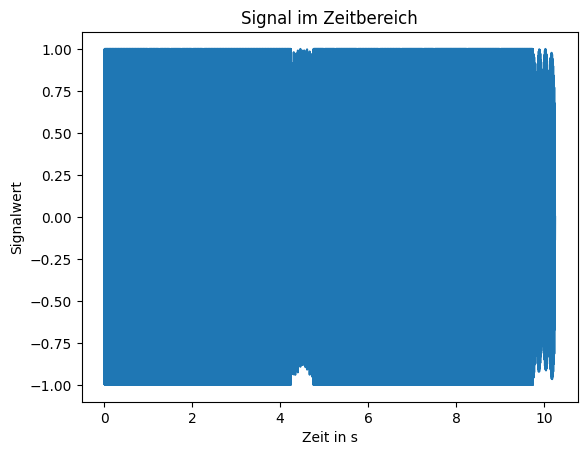

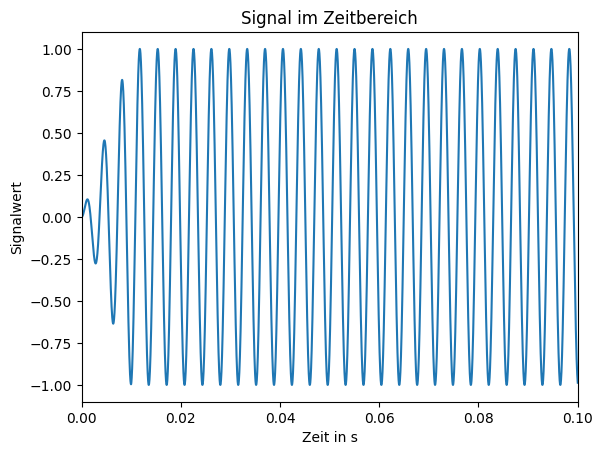

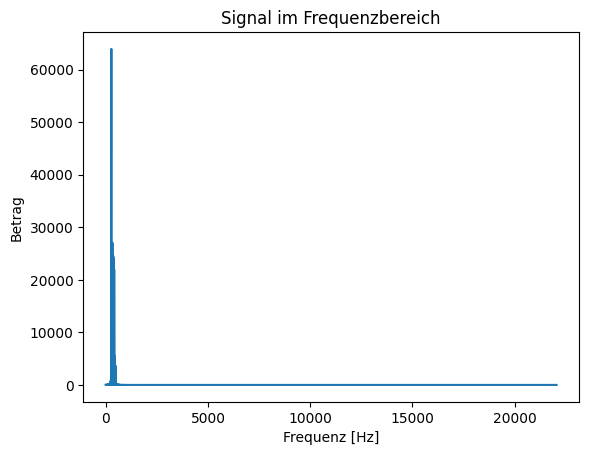

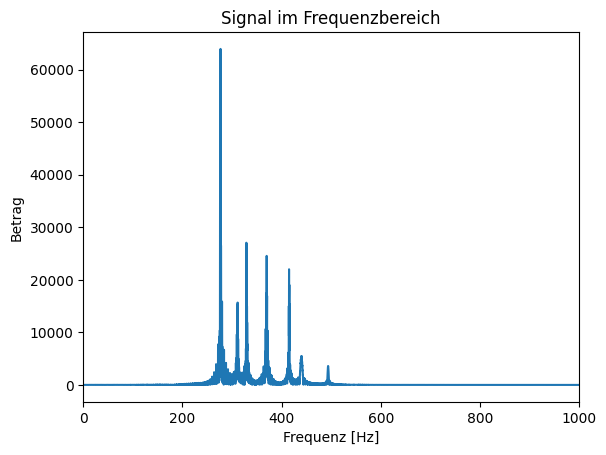

In [14]:
# TODO Plotte die Melodie aus Aufgabe 4:
# - einmal über den gesamten Zeitbereich
plot_zeitbereich(melodie)
# - einmal über den Zeitbereich in den ersten 0.1 Sekunden
plot_zeitbereich(melodie, (0.0, 0.1))
# - einmal über den gesamten positiven Frequenzbereich
plot_frequenzbereich(melodie)
# - einmal über Frequenzbereich von 0 bis 1000 Hz
plot_frequenzbereich(melodie, frequenzfenster=(0.0, 1000.0))
# ------------------------------------------------
# ------------------------------------------------

## Aufgabe 7 - Audiodatei untersuchen (20 Punkte)

Bisher habt ihr eure eigenen Audiodateien erstellt und untersucht. Nun ist ein WAV-Datei `media/verrauschtes_signal.wav` gegeben. Diese soll nun eingelesen und ihre theoretische sowie praktische Dateigröße berechnet und verglichen werden.

Implementiert dazu die vorgegebenen Funktionen gemäß der Beschreibung.

In [15]:
def signaldatei_lesen(dateiname: str) -> tuple[int, np.ndarray]:
    """
    Liest eine WAV-Datei ein und gibt die Abtastrate und das Signal zurück.

    Parameters:
        `dateiname`: Dateiname der WAV-Datei

    Returns:
        Abtastrate und Signal als Tupel z.B. (44100, np.array([...]))
    """

    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Die WAV-Datei einliest.
    abtastrate, signal = wavfile.read(dateiname)
    # 2. Das Signal auf den Bereich von -AMPLITUDE bis AMPLITUDE normalisierst.
    #    Hierfür kann die Funktion `normalisieren` aus Aufgabe 3 verwendet werden.
    signal = normalisieren(signal)
    return abtastrate, signal
    # ------------------------------------------------
    # ------------------------------------------------


def länge_berechnen(signal: np.ndarray, abtastrate: int) -> float:
    """
    Berechnet die Länge des Signals in Sekunden.

    Parameters:
        `signal`: Samples des Signals als Numpy Array
        `abtastrate`: Abtastrate des Signals

    Returns:
        Länge des Signals in Sekunden
    """

    # TODO: Implementiere die Funktion
    return(len(signal) / abtastrate)
    # ------------------------------------------------
    # ------------------------------------------------


def theoretische_dateigröße_berechnen(
    auflösung: int, abtastrate: int, kanal_anzahl: int, dauer: float
) -> float:
    """
    Berechnet die theoretische Dateigröße einer Audiodatei in MebiBytes.

    Parameters:
        `auflösung`: Auflösung in Bit pro Sample
        `abtastrate`: Abtastrate in Samples pro Sekunde
        `kanal_anzahl`: Anzahl der Kanäle
        `dauer`: Dauer des Signals in Sekunden
    """
    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Die Gesamtzahl der Bits berechnest aus Auflösung, Abtastrate, Kanalanzahl und Dauer.
    bits = auflösung * abtastrate * kanal_anzahl * dauer
    # 2. Das Ergebnis in MebiBytes umrechnest.
    mebibytes = bits / (8 * 1024 * 1024)
    return mebibytes
    # ------------------------------------------------
    # ------------------------------------------------


def praktische_dateigröße_berechnen(dateiname: str) -> float:
    """
    Gibt die eigentliche Dateigröße einer Datei in MebiBytes zurück.

    Parameters:
        `dateiname`: Dateiname der Datei

    Returns:
        Dateigröße in MebiBytes
    """

    # TODO: Implementiere die Funktion, indem du
    #
    # 1. Die Dateigröße in Bytes mit ermittelst. Nutze dafür die Funktion `os.path.getsize()`.
    #
    # 2. Das Ergebnis in MebiBytes umrechnest.
    return os.path.getsize(dateiname) / (1024 * 1024)
    # ------------------------------------------------
    # ------------------------------------------------

In [16]:
# TODO Lese die Datei "media/verrauschtes_signal.wav" ein und bestimme dessen Länge und Abtastrate.
#      Gebe Länge und Samplerate in einem geeigneten print-Statement aus.
#      Die Länge soll auf zwei Nachkommastellen gerundet sein.
abtastrate, signal = signaldatei_lesen("media/verrauschtes_signal.wav")
print(f"Länge in Sekunden: {länge_berechnen(signal, abtastrate):.2f} ")
print(f"Abtastrate in Hz: {abtastrate} ")
# ------------------------------------------------
# ------------------------------------------------

# TODO Berechne die theoretische und praktische Dateigröße der Datei "media/verrauschtes_signal.wav".
#      Gebe die theoretische und praktische Dateigröße in einem geeigneten print-Statement aus.
#      Die Dateigröße soll auf sechs Nachkommastellen gerundet sein.
print(f"Theoretische Dateigröße in MebiBytes: {theoretische_dateigröße_berechnen(16, abtastrate, 2, länge_berechnen(signal, abtastrate)):.6f} ")
print(f"Praktische Dateigröße in MebiBytes: {praktische_dateigröße_berechnen('media/verrauschtes_signal.wav'):.6f} ")

# ------------------------------------------------
# ------------------------------------------------

# TODO Wie könnte der Unterschied zwischen theoretischer und praktischer Dateigröße zustande kommen?
# Schreibe einen Kommentar mit möglichen Gründen
# ------------------------------------------------
# Dein Kommentar hier: Bei der theoretischen Dateigröße wird nur die reine Datenmenge berechnet, während die praktische Dateigröße auch Metadaten und komprimierte Daten enthalten kann die die Dateigröße beeinflussen
# ------------------------------------------------

Länge in Sekunden: 12.92 
Abtastrate in Hz: 44100 
Theoretische Dateigröße in MebiBytes: 2.173962 
Praktische Dateigröße in MebiBytes: 1.087023 


## Aufgabe 8 - Signal-Rausch-Verhältnis berechnen (5 Punkte)

Hier soll anhand von gegebenen Werten das Signal-Rausch-Verhältnis berechnet werden.

Implementiert dazu die vorgegebenen Funktionen gemäß der Beschreibung.

In [17]:
def schalldruckpegel_berechnen(effektivschalldruck: np.ndarray, referenzschalldruck: float = 0.00002) -> float:
    """
    Berechnet den Schalldruckpegel in Dezibel anhand von Effektivschalldruck und Referenzschalldruck.

    Parameters:
        `effektivschalldruck`: Effektivschalldruck (p_eff) in Pascal
        `referenzschalldruck`: Referenzschalldruck in Pascal (Standard: 0.00002 Pa)

    Returns:
        Schalldruckpegel in Dezibel
    """
    
    # TODO: Implementiere die Funktion
    
    pressure_ratio = effektivschalldruck / referenzschalldruck
    test = np.log10(pressure_ratio) * 20
    return float(test)
    
    # ------------------------------------------------
    # ------------------------------------------------
nutzpegel_effektivschalldruck = 0.31
nutzpegel = schalldruckpegel_berechnen(nutzpegel_effektivschalldruck, 0.00002)

def snr_berechnen(nutzpegel: float, rauschpegel: float) -> float:
    """
    Berechnet das Signal-Rausch-Verhältnis (SNR) in Dezibel.

    Parameters:
        `nutzpegel`: Schalldruckpegel des Nutzsignals in Dezibel
        `rauschpegel`: Schalldruckpegel des Rauschens in Dezibel

    Returns:
        SNR in Dezibel
    """

    # TODO Implementiere die Funktion
    
    snr = nutzpegel - rauschpegel
    answer = round(snr, 2)
    return float(answer)

    # ------------------------------------------------
    # ------------------------------------------------

In [18]:
# Schalldruckpegel und SNR berechnen

rauschpegel = 73.95  # Gegebener Schalldruckpegel des Rauschens in Dezibel
nutzpegel_effektivschalldruck = 0.31  # Gegebener Effektivschalldruck des Nutzsignals

# TODO Berechne den SNR aus den angegebenen Werten und gebe ihn, gerundet auf 2 Stellen, aus.
#test schalldruckpegel_berechnen(nutzpegel_effektivschalldruck, 0.00002)
snr_berechnen(nutzpegel, rauschpegel)
# ------------------------------------------------
# ------------------------------------------------

9.86

## Aufgabe 9 - Störklang aus Signal entfernen (20 Punkte)

Hört euch die Datei "media/verrauschtes_signal.wav" an. Es ist ein deutliches Störgeräusch zu hören, welches in nun entfernt werden soll. Dafür müssen die Störfrequenzen ermittelt und anschließend entfernt werden.

Implementiert dazu die vorgegebenen Funktionen gemäß der Beschreibung.

In [23]:
def frequenz_entfernen_mit_ftt(
    signal: np.ndarray, zielfrequenz: float, bandbreite: float
) -> np.ndarray:
    """
    Entfernt das angegebene Frequenzband aus dem Signal.

    Parameters:
        `signal`: Signal als Numpy Array
        `zielfrequenz`: Frequenz, die entfernt werden soll (z.B. 440.0 für 440 Hz)
        `bandbreite`: Bereich um die Frequenz, die entfernt werden soll
                      (z.B. werden bei einer Zielfrequenz von 440 Hz und Bandbreite von 20 Hz
                      die Werte aller Frequenzen von 430 Hz bis 450 Hz auf 0 gesetzt)


    Returns:
        Signal, aus dem das Frequenzband entfernt wurde, als Numpy Array
    """

    # TODO: Implementiere die Funktion, indem du
    # 1. Die Fourier-Transformation des Eingabesignals berechnest.
    fr = fft(signal)
    # 2. Die Amplituden der Frequenzkomponenten im Frequenzband um die Zielfrequenz auf Null setzt, um diese zu eliminieren.
    #and was ambigious
    frq = fftfreq(len(signal), 1 / ABTASTRATE)
    fmin = zielfrequenz - bandbreite / 2
    fmax = zielfrequenz + bandbreite / 2
    smth = (np.abs(frq) >= fmin) & (np.abs(frq) <= fmax)
    fr[smth] = 0
    # 3. Eine inverse Fourier-Transformation durchführst, um das bereinigte Signal in den Zeitbereich zurückzutransformieren.
    clean = ifft(fr)
    # 4. Nur den realen Teil des Signals zurückgibst, da das Ergebnis der inversen FFT komplex sein kann.
    return np.real(clean)
    # ------------------------------------------------
    # ------------------------------------------------

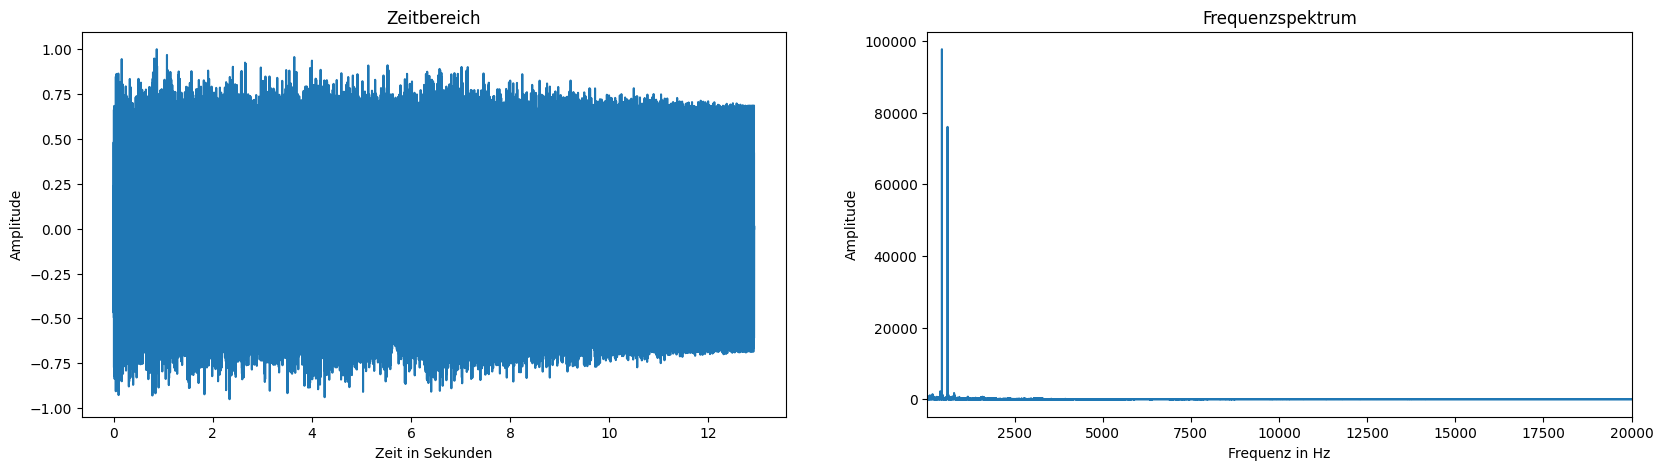

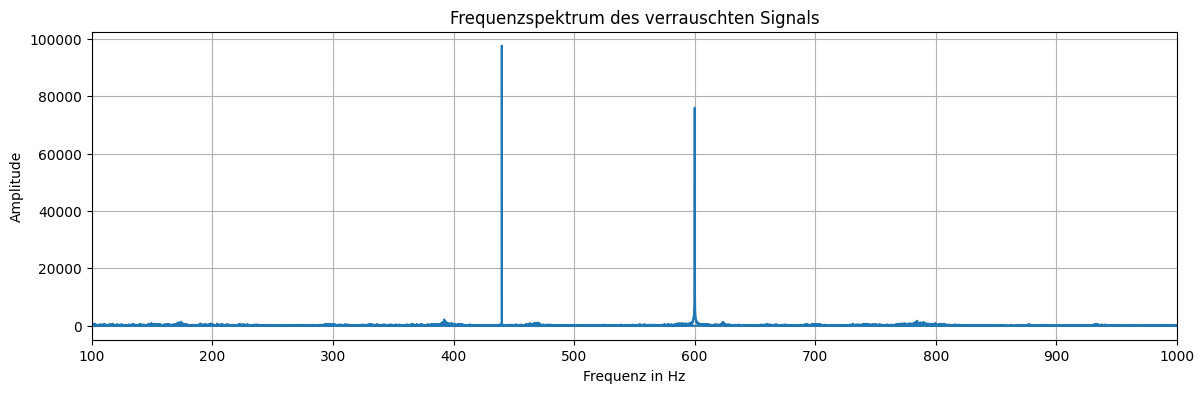

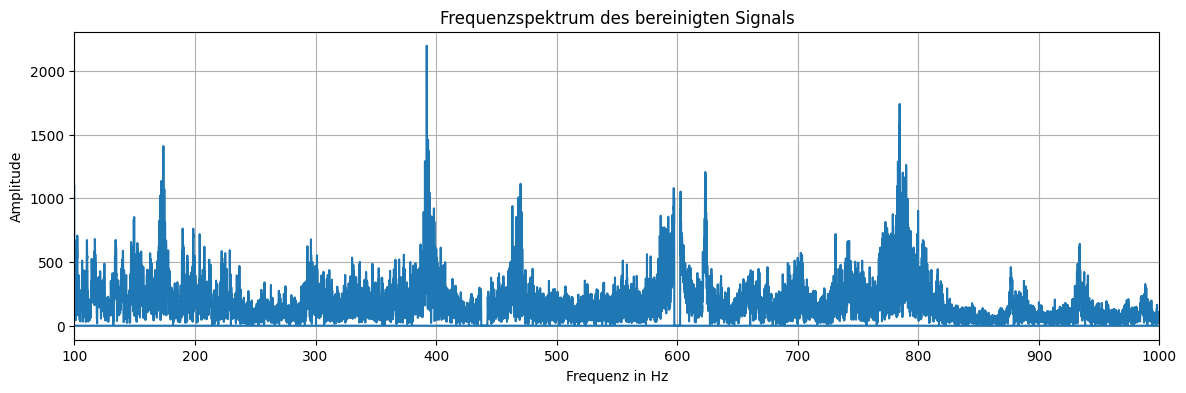

In [24]:
# Datei "media/verrauschtes_signal.wav" einlesen
# die Abtastrate muss nicht weiter verwendet werden, da immer noch die globale Variable ABTASTRATE verwendet wird
abtastrate, verrauschtes_signal = signaldatei_lesen("media/verrauschtes_signal.wav")


# TODO Plotte das verrauschte Signal im Zeit- und Frequenzbereich
#      Es sollen nur menschlich hörbare Frequenzen dargestellt werden.
#needed otherwise undefined
fr = fft(signal)
frq = fftfreq(len(signal), 1 / ABTASTRATE)
amp = np.abs(fr)
#two imgs + zoomin at freqs
sample_count = len(signal)
audio_duration = sample_count / ABTASTRATE
x_values = np.linspace(0, audio_duration, sample_count)

fig, axes = plt.subplots(1, 2, figsize=(20, 5))

axes[0].plot(x_values, signal)
axes[0].set_title("Zeitbereich")
axes[0].set_xlabel("Zeit in Sekunden")
axes[0].set_ylabel("Amplitude")

axes[1].plot(frq, amp)
axes[1].set_title("Frequenzspektrum")
axes[1].set_xlabel("Frequenz in Hz")
axes[1].set_ylabel("Amplitude")
axes[1].set_xlim(20, 20000)

plt.show
# ------------------------------------------------
# ------------------------------------------------

# TODO Finde die Frequenzen der Töne im verrauschten Signal.
#      Schau dir dazu den Frequenzbereich des verrauschten Signals an.
#      Tipp: Passe das Frequenzfenster an, um die Frequenzen genauer zu erkennen.
#grid = полосочки
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(frq, amp)
ax.set_xlim(100, 1000)
ax.set_title("Frequenzspektrum des verrauschten Signals")
ax.set_xlabel("Frequenz in Hz")
ax.set_ylabel("Amplitude")
ax.grid(True)
plt.show()
# ------------------------------------------------
# Die Störfrequenzen sind: bei 440 Hz und 600 Hz.
# ------------------------------------------------

# TODO Entferne die Frequenzen der Töne aus dem verrauschten Signal.
#      Die Bandbreite sollte möglichst gering sein, das Rauschen aber vollständig entfernen.
#      Tipp: Die Funktion `frequenz_entfernen_mit_ftt` kann hierfür mehrfach angewendet werden.
odin = frequenz_entfernen_mit_ftt(verrauschtes_signal, 440, 5)
dva = frequenz_entfernen_mit_ftt(odin, 600, 5)
fr_dva = fft(dva)
frq_dva = fftfreq(len(dva), 1 / ABTASTRATE)
amp_dva = np.abs(fr_dva)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(frq_dva, amp_dva)
ax.set_xlim(100, 1000)
ax.set_title("Frequenzspektrum des bereinigten Signals")
ax.set_xlabel("Frequenz in Hz")
ax.set_ylabel("Amplitude")
ax.grid(True)
plt.show()
#из-за того что мусор убран, зум ин поэтому должно быть нормально..?:??
# ------------------------------------------------
# ------------------------------------------------
# TODO Speichere das entrauschte Signal in der Datei "media/entrauschtes_signal.wav"
#doesn't open otherwise 
max_val = np.max(np.abs(dva))
if max_val > 0:
    normalized_dva = (dva / max_val) * 32767
else:
    normalized_dva = dva

normalized_dva = normalized_dva.astype(np.int16)
wavfile.write("media/entrauschtes_signal.wav", ABTASTRATE, normalized_dva)

# ------------------------------------------------
# ------------------------------------------------

Hört euch die entrauschte Datei an und überprüft, ob ihr den Störklang entfernt habt.